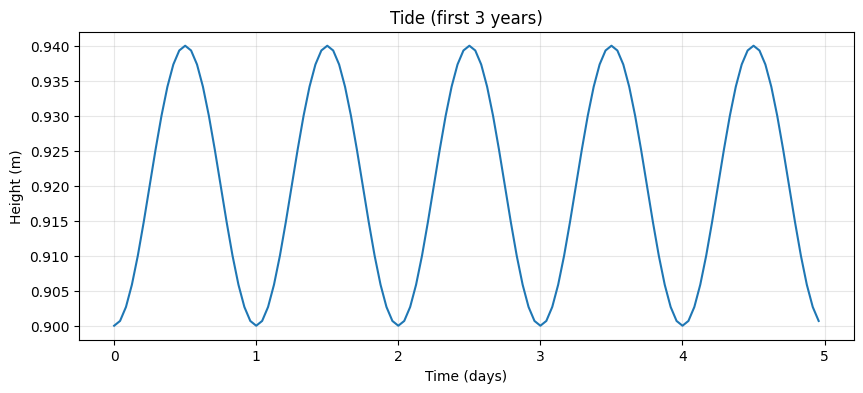

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#low tide at 0.9m, mean level at 0.92m

amplitude = 0.02 # meters
mean_level = 0.92 # meters
period_days = 1 # 1 high and 1 low tide per year
num_years = 10
days_per_year = 365.25
num_days = num_years * days_per_year
samples_per_day = 24

n_points = int(num_days * samples_per_day)
t = np.linspace(0, num_days, n_points)
h = mean_level - amplitude * np.cos(
    2 * np.pi * t / period_days
)

df = pd.DataFrame({
    "time_days": t,
    "height_m": h
})

# Plot to look at curve
window_days = 5
mask = t < window_days

plt.figure(figsize=(10, 4))
plt.plot(t[mask], h[mask])
plt.xlabel("Time (days)")
plt.ylabel("Height (m)")
plt.title("Tide (first 3 years)")
plt.grid(True, alpha=0.3)
plt.show()

# Save file as txt
output_path = "/Users/finleydavis/Desktop/CZN Project/HGS/_repo/tides/tides.txt"

df.to_csv(
    output_path,
    sep=" ",
    index=False,
    header=False,
    float_format="%.6f"
)


# Writes in a way HGS can read
def tide_height(t_days):
    return mean_level - amplitude * np.cos(
        2 * np.pi * t_days / period_days
    )